<a href="https://colab.research.google.com/github/YafetG3/A05-pca/blob/main/a5_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

FileNotFoundError: [Errno 2] No such file or directory: 'data/all_tokens.pickle'

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Yafet Getachew

**Date:** 10/19/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.


##Q1

In [ ]:
import pickle, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

base = "https://raw.githubusercontent.com/YafetG3/A05-pca/main/data/"

# pickle file
with urllib.request.urlopen(base + "all_tokens.pickle") as file:
    all_tokens = pickle.load(file)

# parquet file
df = pd.read_parquet(base + "Phishing_clean.parquet")

In [ ]:
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
print(len(all_tokens), 'tokens;', len(token_count), 'unique')
print(token_freq[:15])
counts = np.array([c for _, c in token_freq])
print('median count:', np.median(counts), '| tokens appearing once:', (counts==1).sum())

276949 tokens; 48691 unique
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644)]
median count: 1.0 | tokens appearing once: 29404


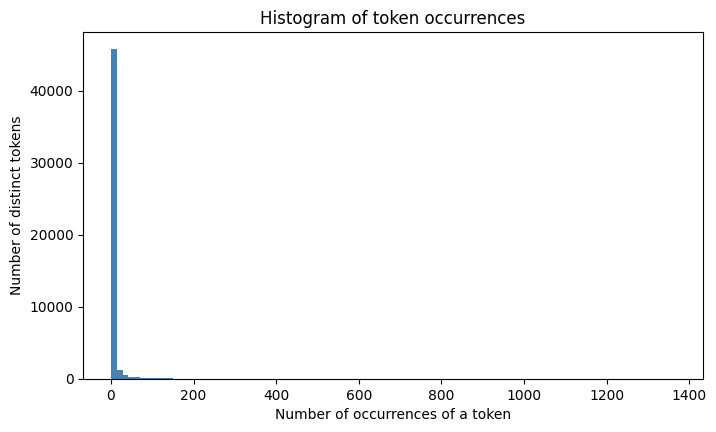

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.hist(counts, bins=100, color='steelblue')
plt.title('Histogram of token occurrences')
plt.xlabel('Number of occurrences of a token'); plt.ylabel('Number of distinct tokens')
plt.show()

The distribution is very rightly-skewed. In the histogram almost all of the tokens are in the first bar, with a long thin tail stretching to the right. Most of the ~48.7k distinct tokens are rare as both the median token and 29,404 tokens (more than the majority) appear exactly once. There are only a handful of tokens that appear 1,000+ times.

##Q2

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

y = df['Email Type']
X = df.drop(columns='Email Type')
print(X.shape, 'share of scams: %.3f' % y.mean())

# 1. 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(18634, 2711) share of scams: 0.392
(14907, 2711) (3727, 2711)


In [ ]:
# 2. Linear regression of y on X
lm = LinearRegression().fit(X_train, y_train)
print('Train R2: %.4f' % lm.score(X_train, y_train))
print('Test  R2: %.4f' % lm.score(X_test, y_test))

Train R2: 0.7670
Test  R2: 0.6659


In [ ]:
# 3. Largest |coefficients|
coef = pd.Series(lm.coef_, index=X.columns)
top = coef.reindex(coef.abs().sort_values(ascending=False).index)
print(top.head(20).round(3))

intervention        -1.259
localized            0.824
thermal              0.747
crawler              0.696
background-image:   -0.623
helvetica,           0.599
aging                0.595
form.                0.577
gray;               -0.574
a:active             0.574
retrieving          -0.574
zdnet               -0.561
{text-decoration:    0.497
xanaax               0.492
transcript           0.489
shopper             -0.487
april's             -0.486
arial,              -0.482
laser                0.474
issue:              -0.466
dtype: float64


- Train $R^2 \approx 0.767$ while test $R^2 \approx 0.666$.
- The gap of about 0.10 means the model overfits somewhat: 2,711 features on ~14.9k training e-mails lets OLS fit noise.
- The largest-magnitude coefficients are "intervention", "localized", "thermal", "crawler", and "background-image:"
- Positive coefficients push the prediction toward scam while negative pushes it toward legitimate. --> Caveat: tokens are highly correlated with each other (overlapping information) and many are rare, so individual coefficients are unstable and being large does not necessarily mean the word is the most predictive.

##Q3

Variance explained by PC1, PC2: [0.0111 0.0086] | total: 0.0197


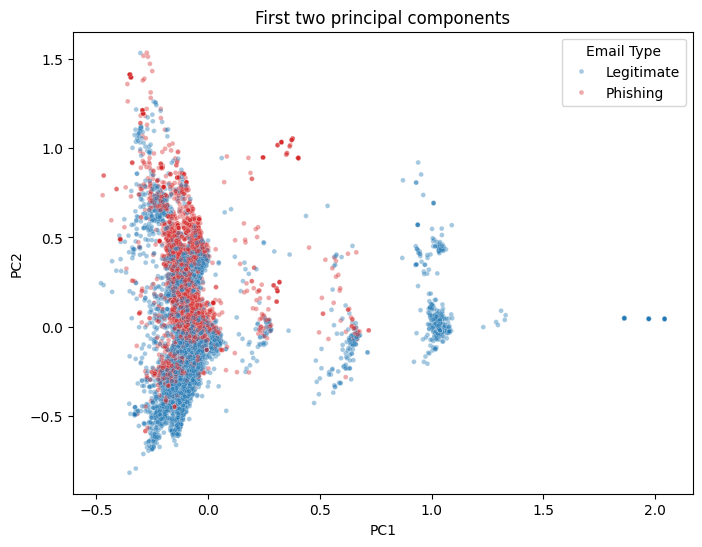

In [ ]:
# PCA is unsupervised, so we use X only (no y). sklearn centers the columns for us.
# All columns are 0/1 indicators on the same scale, so we do not rescale them.
pca2 = PCA(n_components=2).fit(X)
Z = pca2.transform(X)
print('Variance explained by PC1, PC2:', pca2.explained_variance_ratio_.round(4),
      '| total: %.4f' % pca2.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y.map({0: 'Legitimate', 1: 'Phishing'}), alpha=0.4, s=12,
                palette={'Legitimate': 'tab:blue', 'Phishing': 'tab:red'})
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('First two principal components'); plt.show()

Two components explain only about 2% of the total variance, so this plot is a very lossy summary of 2,711 dimensions.
- Still, there is structure: most e-mails form a dense band at low PC1, with phishing e-mails (red) concentrated in the middle/upper part and legitimate e-mails (blue) toward the bottom, so PC2 separates the classes partially.
- The classes overlap heavily, so two components alone can’t cleanly classify.
- There are also tight clusters at larger PC1 (about 0.6 and 1.0) that are almost all legitimate, plus a few far-out points near PC1 = 2, probably groups of near-duplicate e-mails (mailing lists, threads) sharing the same tokens.

##Q4

In [ ]:
# Fit PCA on the training data only (avoids leakage), then project train and test onto the same components
pca = PCA(n_components=2610).fit(X_train)
P_train = pca.transform(X_train)
P_test = pca.transform(X_test)
print('Variance retained by 2,610 components: %.4f' % pca.explained_variance_ratio_.sum())

pcr = LinearRegression().fit(P_train, y_train)
print('PCR  Train R2: %.4f | Test R2: %.4f' % (pcr.score(P_train, y_train), pcr.score(P_test, y_test)))
print('OLS  Train R2: %.4f | Test R2: %.4f' % (lm.score(X_train, y_train), lm.score(X_test, y_test)))

Variance retained by 2,610 components: 0.9999
PCR  Train R2: 0.7662 | Test R2: 0.6683
OLS  Train R2: 0.7670 | Test R2: 0.6659


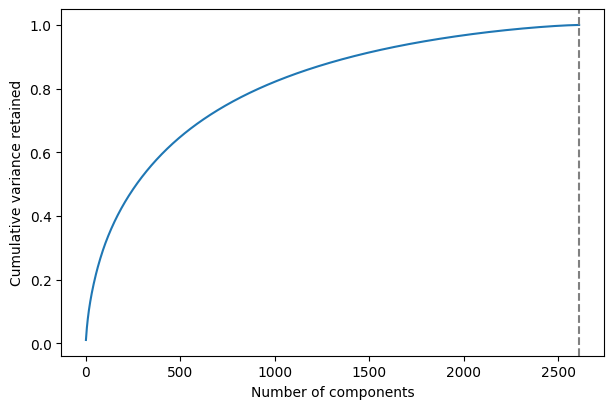

Components needed to retain >= 95% of variance: 1806


In [ ]:
# Variance retained vs. number of components
cum = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(7, 4.5)); plt.plot(np.arange(1, len(cum)+1), cum)
plt.axvline(2610, ls='--', color='gray')
plt.xlabel('Number of components'); plt.ylabel('Cumulative variance retained'); plt.show()
print('Components needed to retain >= 95% of variance:', int(np.argmax(cum >= 0.95)) + 1)

With 2,610 components, train $R^2 \approx 0.766$ and test $R^2 \approx 0.668$, essentially identical to the plain regression (0.767 / 0.666). This makes sense: the 2,610 components retain 99.99% of the variance, so we only dropped the ~100 smallest directions and the model is almost the same as using all 2,711 original columns. Keeping this many components gives almost no regularization benefit. The table of $R^2$ by $k$ shows test $R^2$ rises with $k$ (0.105 at k=2, 0.514 at k=100, 0.657 at k=1000) and peaks around k=2000 (0.674), only slightly above k=2610 (0.668), while train $R^2$ keeps climbing, so the gap between train and test grows as we add components. Dropping the last few hundred components trims a little overfitting, but cutting much further loses real signal, so $k$ should be chosen by variance retained (the lecture rule of keeping enough components to retain at least 95% of the variance, which needs about 1,806 here) or by cross-validation.

##Q5

Many of the 2,711 word columns measure related things and carry overlapping information (words that tend to appear together). As in lecture, PCA combines these features into new variables, so we can keep fewer variables while preserving most of the variation in the data. The component scores are uncorrelated with each other and ordered by how much variance they capture, and lecture notes we can use them as features for regression. This helps because (1) it removes the multicollinearity that makes OLS coefficients unstable, (2) we can keep only the top components and drop low-variance directions that are mostly noise, so we estimate far fewer parameters, reduce overfitting and speed up the fit, and (3) it makes high-dimensional data easier to work with and visualize. The trade-off is that each component is a blend of many words, so it is harder to interpret than a single word’s coefficient, and PCA is unsupervised (it ignores $y$), so the kept directions are not guaranteed to be the most predictive of scam vs. not.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]